# 03: Subsample for cp_measure

We have close to a million cells - let's subsample 50k each to featurise

In [1]:
import spatialdata as sd
import spatialdata_plot
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.pyplot as plt
from spatialdata.models import TableModel, Labels2DModel
import anndata as ad
import xarray as xr
import dask.array as da
import numpy as np

/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/importlib/__init__.py:126: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  return _bootstrap._gcd_import(name[level:], package, level)


In [2]:
proj_dir = Path("/lustre/groups/ml01/projects/2025_ttreis_icml_cpmeasure")
data_dir = proj_dir / Path("data")

In [3]:
sdata_sample1 = sd.read_zarr(data_dir / "xenium_sample1.zarr")
sdata_sample2 = sd.read_zarr(data_dir / "xenium_sample2.zarr")

version mismatch: detected: RasterFormatV02, requested: FormatV04
/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/zarr/creation.py:610: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwargs)
version mismatch: detected: RasterFormatV02, requested: FormatV04
version mismatch: detected: RasterFormatV02, requested: FormatV04
version mismatch: detected: RasterFormatV02, requested: FormatV04
/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/zarr/creation.py:610: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwargs)
version mismatch: detected: RasterFormatV02, requested: FormatV04
version mismatch: detected: RasterFormatV02, requested: FormatV04


## Load celltypes for stratification

In [ ]:
adata = ad.read_h5ad(data_dir / "xenium_gexp_celltypes.h5ad")
adata

AnnData object with n_obs × n_vars = 940131 × 380
    obs: 'cell_id', 'transcript_counts', 'control_probe_counts', 'control_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'region', 'sample', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'leiden', 'Adipocytes_score', 'B cells_score', 'Breast cancer_score', 'Breast glandular cells_score', 'Breast myoepithelial cells_score', 'Dendritic cells_score', 'Endothelial cells_score', 'Epithelial cells_score', 'Fibroblasts_score', 'Immune cells_score', 'Macrophages_score', 'Mast cells_score', 'Monocytes_score', 'NK cells_score', 'Smooth muscle cells_score', 'T cells_score', 'predicted_celltype'
    var: 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'lo

In [ ]:
adata.obs["predicted_celltype"].value_counts()

predicted_celltype
Breast cancer                 350506
Fibroblasts                   136054
Epithelial cells              132406
Immune cells                  117588
Breast glandular cells         74049
Endothelial cells              35699
Monocytes                      28786
Breast myoepithelial cells     27527
Mast cells                      9893
Smooth muscle cells             8822
Macrophages                     5785
Dendritic cells                 2958
B cells                         2664
NK cells                        2557
T cells                         2425
Adipocytes                      2221
Unknown                          191
Name: count, dtype: int64

In [ ]:
adata = adata[adata.obs["predicted_celltype"] != "Unknown"].copy()

# Stratified sampling: up to 5000 cells per sample
sampled_indices = (
    adata.obs
    .groupby(["sample", "predicted_celltype"], group_keys=False)
    .apply(lambda x: x.sample(min(len(x), 5000), random_state=42))
    .index
)

# Subset the adata object
adata_sampled = adata[sampled_indices].copy()
adata_sampled

/tmp/ipykernel_177096/1166370379.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(["sample", "predicted_celltype"], group_keys=False)
/tmp/ipykernel_177096/1166370379.py:7: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.sample(min(len(x), 5000), random_state=42))


AnnData object with n_obs × n_vars = 113534 × 380
    obs: 'cell_id', 'transcript_counts', 'control_probe_counts', 'control_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'region', 'sample', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'leiden', 'Adipocytes_score', 'B cells_score', 'Breast cancer_score', 'Breast glandular cells_score', 'Breast myoepithelial cells_score', 'Dendritic cells_score', 'Endothelial cells_score', 'Epithelial cells_score', 'Fibroblasts_score', 'Immune cells_score', 'Macrophages_score', 'Mast cells_score', 'Monocytes_score', 'NK cells_score', 'Smooth muscle cells_score', 'T cells_score', 'predicted_celltype'
    var: 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'lo

In [7]:
adata_sampled[adata_sampled.obs["sample"] == "sample1"].obs["predicted_celltype"].value_counts()

predicted_celltype
Breast glandular cells        5000
Breast cancer                 5000
Endothelial cells             5000
Breast myoepithelial cells    5000
Epithelial cells              5000
Smooth muscle cells           5000
Immune cells                  5000
Fibroblasts                   5000
Monocytes                     5000
Mast cells                    4481
Macrophages                   3682
B cells                       1741
Dendritic cells               1727
NK cells                      1668
T cells                       1570
Adipocytes                    1209
Name: count, dtype: int64

In [8]:
adata_sampled[adata_sampled.obs["sample"] == "sample2"].obs["predicted_celltype"].value_counts()

predicted_celltype
Breast glandular cells        5000
Breast cancer                 5000
Endothelial cells             5000
Fibroblasts                   5000
Monocytes                     5000
Mast cells                    5000
Immune cells                  5000
Epithelial cells              4912
Smooth muscle cells           3122
Breast myoepithelial cells    2409
Macrophages                   2103
Dendritic cells               1231
Adipocytes                    1012
B cells                        923
NK cells                       889
T cells                        855
Name: count, dtype: int64

In [9]:
adata_sub_s1 = adata_sampled[adata_sampled.obs["sample"] == "sample1"]
adata_sub_s2 = adata_sampled[adata_sampled.obs["sample"] == "sample2"]

### Subset sdata objects

#### Sample 1

In [10]:
adata_sub_s1.obs

,cell_id,transcript_counts,control_probe_counts,control_codeword_counts,total_counts,cell_area,nucleus_area,region,sample,n_genes_by_counts,...,Epithelial cells_score,Fibroblasts_score,Immune cells_score,Macrophages_score,Mast cells_score,Monocytes_score,NK cells_score,Smooth muscle cells_score,T cells_score,predicted_celltype
41188,41189,222,0,0,222.0,212.866563,49.220312,cell_circles,sample1,98,...,-0.285647,0.013188,-0.386753,-0.152401,-0.056226,-0.190969,-0.114832,0.183085,-0.048610,Adipocytes
174841,174842,135,0,0,135.0,126.347188,8.037813,cell_circles,sample1,74,...,-0.063004,-0.096821,-0.083749,0.083670,-0.085120,0.110979,0.012362,-0.087251,-0.062735,Adipocytes
126965,126966,70,0,0,70.0,104.220625,18.243125,cell_circles,sample1,47,...,-0.276079,0.022820,-0.295929,-0.024960,-0.021954,-0.120597,-0.154878,-0.190069,-0.117785,Adipocytes
43084,43085,171,0,0,171.0,165.181563,5.644531,cell_circles,sample1,61,...,-0.373689,0.063771,-0.174921,0.062002,-0.153130,0.138751,-0.082430,0.085674,-0.070772,Adipocytes
488409,488410,134,0,0,134.0,603.558438,9.753750,cell_circles,sample1,45,...,-0.005206,0.059030,-0.084212,-0.090931,-0.185985,-0.167230,-0.135307,0.024822,-0.085685,Adipocytes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
445414,445415,39,0,0,39.0,35.944375,14.585469,cell_circles,sample1,30,...,-0.148117,0.025095,0.000000,0.027503,-0.061897,-0.136250,-0.069673,-0.157584,0.272008,T cells
519202,519203,50,0,0,50.0,66.379688,25.287500,cell_circles,sample1,40,...,-0.180531,0.253304,0.000000,0.061381,-0.107728,-0.208023,0.110176,-0.185501,0.620082,T cells
336621,336622,54,0,0,54.0,90.086719,14.630625,cell_circles,sample1,35,...,-0.159917,0.286309,0.000000,-0.058180,0.000000,-0.102074,-0.052197,-0.221681,0.472617,T cells
542264,542265,93,0,0,93.0,153.170000,21.765313,cell_circles,sample1,58,...,-0.307216,0.167299,-0.352746,0.137866,-0.018206,-0.147182,0.116758,-0.033334,0.222358,T cells


In [11]:
from anndata import AnnData

def sanitize_name(name: str, is_dataframe_column: bool = False) -> str:
    """
    Sanitize a name to comply with SpatialData naming rules.
    This function converts invalid names into valid ones by:
    1. Converting to string if not already
    2. Removing invalid characters
    3. Handling special cases like "__" prefix
    4. Ensuring the name is not empty
    5. Handling special cases for dataframe columns
    Parameters
    ----------
    name
        The name to sanitize
    is_dataframe_column
        Whether this name is for a dataframe column (additional restrictions apply)
    Returns
    -------
    A sanitized version of the name that complies with SpatialData naming rules.
    Examples
    --------
    >>> sanitize_name("my@invalid#name")
    'my_invalid_name'
    >>> sanitize_name("__private")
    'private'
    >>> sanitize_name("_index", is_dataframe_column=True)
    'index'
    """
    # Convert to string if not already
    name = str(name)

    # Handle empty string case
    if not name:
        return "unnamed"

    # Handle special cases
    if name == "." or name == "..":
        return "unnamed"

    # Remove "__" prefix if present
    if name.startswith("__"):
        name = name[2:]

    # Replace invalid characters with underscore
    # Keep only alphanumeric, underscore, dot, and hyphen
    sanitized = ""
    for char in name:
        if char.isalnum() or char in "_-.":
            sanitized += char
        else:
            sanitized += "_"

    # Remove leading underscores but keep trailing ones
    sanitized = sanitized.lstrip("_")

    # Ensure we don't end up with an empty string after sanitization
    if not sanitized:
        return "unnamed"

    return sanitized


def sanitize_table(data: AnnData, inplace: bool = True) -> AnnData | None:
    """
    Sanitize all keys in an AnnData table to comply with SpatialData naming rules.
    This function sanitizes all keys in obs, var, obsm, obsp, varm, varp, uns, and layers
    while maintaining case-insensitive uniqueness. It can either modify the table in-place
    or return a new sanitized copy.
    Parameters
    ----------
    data
        The AnnData table to sanitize
    inplace
        Whether to modify the table in-place or return a new copy
    Returns
    -------
    If inplace is False, returns a new AnnData object with sanitized keys.
    If inplace is True, returns None as the original object is modified.
    Examples
    --------
    >>> import anndata as ad
    >>> adata = ad.AnnData(obs=pd.DataFrame({"@invalid#": [1, 2]}))
    >>> # Create a new sanitized copy
    >>> sanitized = sanitize_table(adata)
    >>> print(sanitized.obs.columns)
    Index(['invalid_'], dtype='object')
    >>> # Or modify in-place
    >>> sanitize_table(adata, inplace=True)
    >>> print(adata.obs.columns)
    Index(['invalid_'], dtype='object')
    """
    import copy
    from collections import defaultdict

    # Create a deep copy if not modifying in-place
    sanitized = data if inplace else copy.deepcopy(data)

    # Track used names to maintain case-insensitive uniqueness
    used_names: dict[str, set[str]] = defaultdict(set)

    def get_unique_name(name: str, attr: str, is_dataframe_column: bool = False) -> str:
        base_name = sanitize_name(name, is_dataframe_column)
        normalized_base = base_name.lower()

        # If this exact name is already used, add a number
        if normalized_base in {n.lower() for n in used_names[attr]}:
            counter = 1
            while f"{base_name}_{counter}".lower() in {n.lower() for n in used_names[attr]}:
                counter += 1
            base_name = f"{base_name}_{counter}"

        used_names[attr].add(base_name)
        return base_name

    # Handle obs and var (dataframe columns)
    for attr in ("obs", "var"):
        df = getattr(sanitized, attr)
        new_columns = {old: get_unique_name(old, attr, is_dataframe_column=True) for old in df.columns}
        df.rename(columns=new_columns, inplace=True)

    # Handle other attributes
    for attr in ("obsm", "obsp", "varm", "varp", "uns", "layers"):
        d = getattr(sanitized, attr)
        new_keys = {old: get_unique_name(old, attr) for old in d}
        # Create new dictionary with sanitized keys
        new_dict = {new_keys[old]: value for old, value in d.items()}
        setattr(sanitized, attr, new_dict)

    return None if inplace else sanitized

In [12]:
sanitize_table(adata_sub_s1, inplace=True)
sanitize_table(adata_sub_s2, inplace=True)

In [13]:
sdata_sample1.tables["table_subset"] = TableModel.parse(adata_sub_s1)
sdata_sample2.tables["table_subset"] = TableModel.parse(adata_sub_s2)

In [14]:
sdata_sample1.tables["table_subset"].uns["spatialdata_attrs"] = sdata_sample1.tables["table"].uns["spatialdata_attrs"]
sdata_sample2.tables["table_subset"].uns["spatialdata_attrs"] = sdata_sample2.tables["table"].uns["spatialdata_attrs"]

In [15]:
sdata_sample1

SpatialData object, with associated Zarr store: /ictstr01/groups/ml01/projects/2025_ttreis_icml_cpmeasure/data/xenium_sample1.zarr
├── Images
│     ├── 'hne': DataTree[cyx] (3, 42947, 38096), (3, 21473, 19048), (3, 10736, 9524), (3, 5368, 4762)
│     ├── 'morphology_focus': DataTree[cyx] (1, 53833, 48441), (1, 26916, 24220), (1, 13458, 12110), (1, 6729, 6055), (1, 3364, 3027)
│     └── 'morphology_mip': DataTree[cyx] (1, 53833, 48441), (1, 26916, 24220), (1, 13458, 12110), (1, 6729, 6055), (1, 3364, 3027)
├── Labels
│     ├── 'cell_labels': DataTree[yx] (53833, 48441), (26916, 24220), (13458, 12110), (6729, 6055), (3364, 3027)
│     └── 'nucleus_labels': DataTree[yx] (53833, 48441), (26916, 24220), (13458, 12110), (6729, 6055), (3364, 3027)
├── Points
│     └── 'transcripts': DataFrame with shape: (<Delayed>, 8) (3D points)
├── Shapes
│     ├── 'cell_boundaries': GeoDataFrame shape: (574527, 1) (2D shapes)
│     ├── 'cell_circles': GeoDataFrame shape: (574527, 2) (2D shapes)
│     └── 

In [16]:
sdata_sample2

SpatialData object, with associated Zarr store: /ictstr01/groups/ml01/projects/2025_ttreis_icml_cpmeasure/data/xenium_sample2.zarr
├── Images
│     ├── 'hne': DataTree[cyx] (3, 34537, 38096), (3, 17268, 19048), (3, 8634, 9524), (3, 4317, 4762)
│     ├── 'morphology_focus': DataTree[cyx] (1, 41411, 45749), (1, 20705, 22874), (1, 10352, 11437), (1, 5176, 5718), (1, 2588, 2859)
│     └── 'morphology_mip': DataTree[cyx] (1, 41411, 45749), (1, 20705, 22874), (1, 10352, 11437), (1, 5176, 5718), (1, 2588, 2859)
├── Labels
│     ├── 'cell_labels': DataTree[yx] (41411, 45749), (20705, 22874), (10352, 11437), (5176, 5718), (2588, 2859)
│     └── 'nucleus_labels': DataTree[yx] (41411, 45749), (20705, 22874), (10352, 11437), (5176, 5718), (2588, 2859)
├── Points
│     └── 'transcripts': DataFrame with shape: (<Delayed>, 8) (3D points)
├── Shapes
│     ├── 'cell_boundaries': GeoDataFrame shape: (365604, 1) (2D shapes)
│     ├── 'cell_circles': GeoDataFrame shape: (365604, 2) (2D shapes)
│     └── '

### Modify labels object to only include cells in the subset adata

In [17]:
sdata_sample1["cell_labels"]["scale0"].image

<xarray.DataArray 'image' (y: 53833, x: 48441)> Size: 10GB
dask.array<from-zarr, shape=(53833, 48441), dtype=uint32, chunksize=(4096, 4096), chunktype=numpy.ndarray>
Coordinates:
  * y        (y) float64 431kB 0.5 1.5 2.5 3.5 ... 5.383e+04 5.383e+04 5.383e+04
  * x        (x) float64 388kB 0.5 1.5 2.5 3.5 ... 4.844e+04 4.844e+04 4.844e+04
Attributes:
    transform:  {'global': Identity }

In [18]:
sdata_sample1["table_subset"].obs["cell_id"]

41188      41189
174841    174842
126965    126966
43084      43085
488409    488410
           ...  
445414    445415
519202    519203
336621    336622
542264    542265
445157    445158
Name: cell_id, Length: 61078, dtype: int32

In [19]:
valid_ids = sdata_sample1["table_subset"].obs["cell_id"].values

data = sdata_sample1["cell_labels"]["scale0"].image.data
keep = da.isin(data, valid_ids)

# 4. zero out any label not in valid_ids
filtered_data = da.where(keep, data, 0)

# 5. wrap back into a DataArray (preserves coords, attrs, chunksize)
filtered_mask = sdata_sample1["cell_labels"]["scale0"].image.copy(data=filtered_data)
filtered_mask

<xarray.DataArray 'image' (y: 53833, x: 48441)> Size: 10GB
dask.array<where, shape=(53833, 48441), dtype=uint32, chunksize=(4096, 4096), chunktype=numpy.ndarray>
Coordinates:
  * y        (y) float64 431kB 0.5 1.5 2.5 3.5 ... 5.383e+04 5.383e+04 5.383e+04
  * x        (x) float64 388kB 0.5 1.5 2.5 3.5 ... 4.844e+04 4.844e+04 4.844e+04
Attributes:
    transform:  {'global': Identity }

In [24]:
sdata_sample1.labels["cell_labels_subset"] = Labels2DModel.parse(
    filtered_mask,
    scale_factors=[2, 2, 2, 2]
)

In [26]:
sdata_sample1.write(data_dir / "xenium_sample1_subset.zarr", overwrite=True)

INFO     The SpatialData object is not self-contained (i.e. it contains some elements that are Dask-backed from    
         locations outside                                                                                         
         /lustre/groups/ml01/projects/2025_ttreis_icml_cpmeasure/data/xenium_sample1_subset.zarr). Please see the  
         documentation of `is_self_contained()` to understand the implications of working with SpatialData objects 
         that are not self-contained.                                                                              
INFO     The Zarr backing store has been changed from                                                              
         /lustre/groups/ml01/projects/2025_ttreis_icml_cpmeasure/data/xenium_sample1.zarr the new file path:       
         /lustre/groups/ml01/projects/2025_ttreis_icml_cpmeasure/data/xenium_sample1_subset.zarr                   


In [4]:
sdata_sample1 = sd.read_zarr(data_dir / "xenium_sample1_subset.zarr")

version mismatch: detected: RasterFormatV02, requested: FormatV04
/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/zarr/creation.py:610: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwargs)
version mismatch: detected: RasterFormatV02, requested: FormatV04
version mismatch: detected: RasterFormatV02, requested: FormatV04


/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/functools.py:909: UserWarning: The object has `points` element. Depending on the number of points, querying MAY suffer from performance issues. Please consider filtering the object before calling this function by calling the `subset()` method of `SpatialData`.
  return dispatch(args[0].__class__)(*args, **kw)


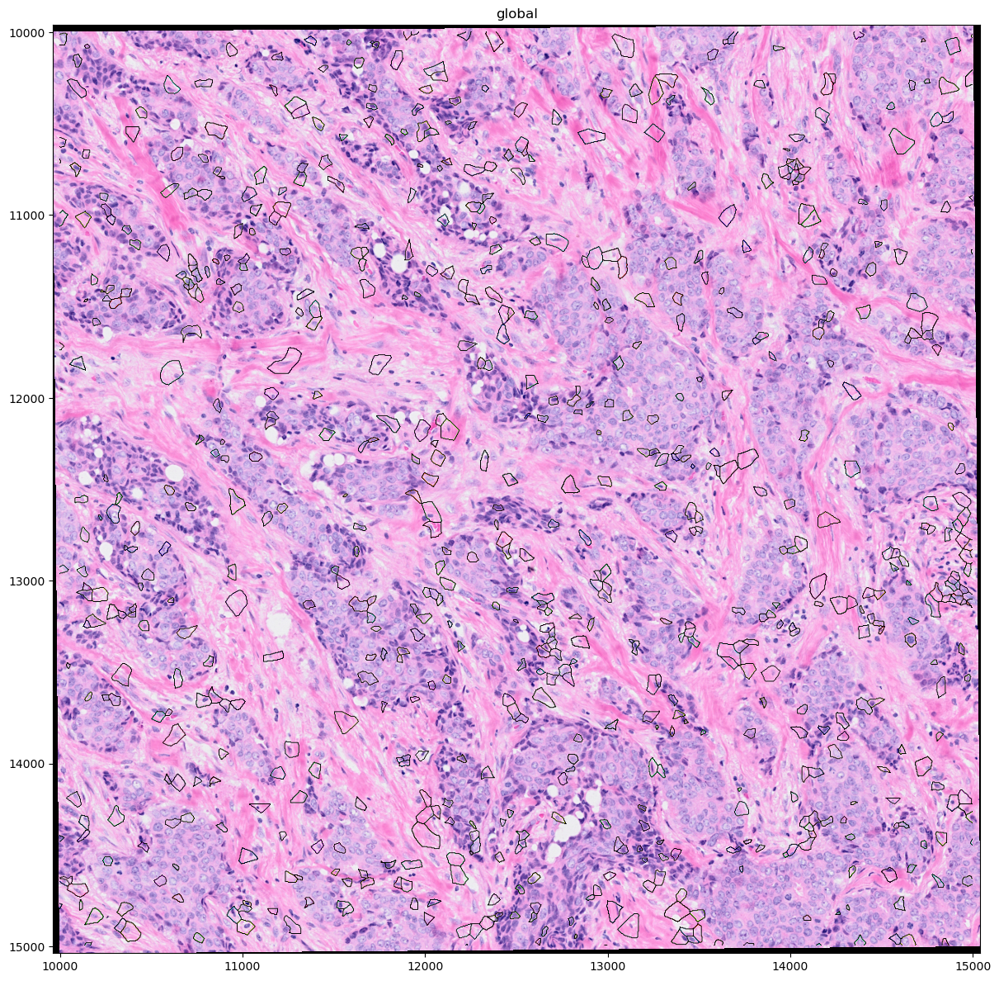

In [31]:
(
    sdata_sample1
    .query.bounding_box(
        axes=["x", "y"],
        min_coordinate=[10000, 10000],
        max_coordinate=[15000, 15000],
        target_coordinate_system="global",
    )
    .pl.render_images("hne")
    .pl.render_labels("cell_labels_subset", fill_alpha=0, outline_alpha=1)
    .pl.show(figsize=(12, 12))
)

### sample2

In [32]:
valid_ids = sdata_sample2["table_subset"].obs["cell_id"].values

data = sdata_sample2["cell_labels"]["scale0"].image.data
keep = da.isin(data, valid_ids)

# 4. zero out any label not in valid_ids
filtered_data = da.where(keep, data, 0)

# 5. wrap back into a DataArray (preserves coords, attrs, chunksize)
filtered_mask = sdata_sample2["cell_labels"]["scale0"].image.copy(data=filtered_data)
filtered_mask

<xarray.DataArray 'image' (y: 41411, x: 45749)> Size: 8GB
dask.array<where, shape=(41411, 45749), dtype=uint32, chunksize=(4096, 4096), chunktype=numpy.ndarray>
Coordinates:
  * y        (y) float64 331kB 0.5 1.5 2.5 3.5 ... 4.141e+04 4.141e+04 4.141e+04
  * x        (x) float64 366kB 0.5 1.5 2.5 3.5 ... 4.575e+04 4.575e+04 4.575e+04
Attributes:
    transform:  {'global': Identity }

In [33]:
sdata_sample2.labels["cell_labels_subset"] = Labels2DModel.parse(
    filtered_mask,
    scale_factors=[2, 2, 2, 2]
)

In [34]:
sdata_sample2.write(data_dir / "xenium_sample2_subset.zarr", overwrite=True)

INFO     The SpatialData object is not self-contained (i.e. it contains some elements that are Dask-backed from    
         locations outside                                                                                         
         /lustre/groups/ml01/projects/2025_ttreis_icml_cpmeasure/data/xenium_sample2_subset.zarr). Please see the  
         documentation of `is_self_contained()` to understand the implications of working with SpatialData objects 
         that are not self-contained.                                                                              
INFO     The Zarr backing store has been changed from                                                              
         /lustre/groups/ml01/projects/2025_ttreis_icml_cpmeasure/data/xenium_sample2.zarr the new file path:       
         /lustre/groups/ml01/projects/2025_ttreis_icml_cpmeasure/data/xenium_sample2_subset.zarr                   


In [5]:
sdata_sample2 = sd.read_zarr(data_dir / "xenium_sample2_subset.zarr")

version mismatch: detected: RasterFormatV02, requested: FormatV04
/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/zarr/creation.py:610: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwargs)
version mismatch: detected: RasterFormatV02, requested: FormatV04
version mismatch: detected: RasterFormatV02, requested: FormatV04


/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/functools.py:909: UserWarning: The object has `points` element. Depending on the number of points, querying MAY suffer from performance issues. Please consider filtering the object before calling this function by calling the `subset()` method of `SpatialData`.
  return dispatch(args[0].__class__)(*args, **kw)


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.015936255..1.0].


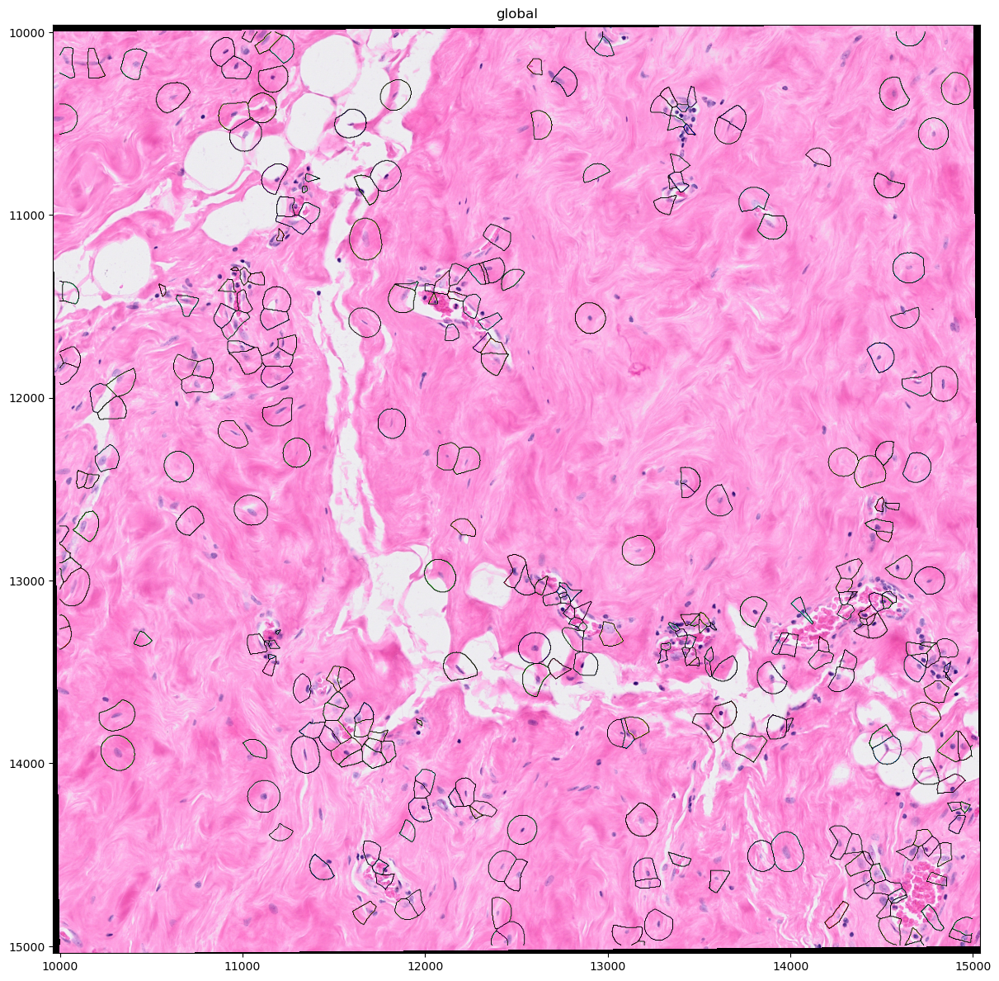

In [6]:
(
    sdata_sample2
    .query.bounding_box(
        axes=["x", "y"],
        min_coordinate=[10000, 10000],
        max_coordinate=[15000, 15000],
        target_coordinate_system="global",
    )
    .pl.render_images("hne")
    .pl.render_labels("cell_labels_subset", fill_alpha=0, outline_alpha=1)
    .pl.show(figsize=(12, 12))
)

In [5]:
crop = sdata_sample1.query.bounding_box(
    axes=["x", "y"],
    min_coordinate=[10000, 10000],
    max_coordinate=[15000, 15000],
    target_coordinate_system="global",
)

/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/functools.py:909: UserWarning: The object has `points` element. Depending on the number of points, querying MAY suffer from performance issues. Please consider filtering the object before calling this function by calling the `subset()` method of `SpatialData`.
  return dispatch(args[0].__class__)(*args, **kw)


In [6]:
from spatialdata.transformations import get_transformation

get_transformation(crop["hne"]).to_affine_matrix(input_axes=("x", "y"), output_axes=("x", "y"))

array([[ 1.28878183e+00, -1.00712658e-02,  1.00005592e+04],
       [-1.00712658e-02, -1.28878183e+00,  1.50379073e+04],
       [ 0.00000000e+00,  0.00000000e+00,  1.00000000e+00]])

In [8]:
hne_transformed = sd.transform(crop["hne"], to_coordinate_system="global")
crop.images["hne_2"] = hne_transformed

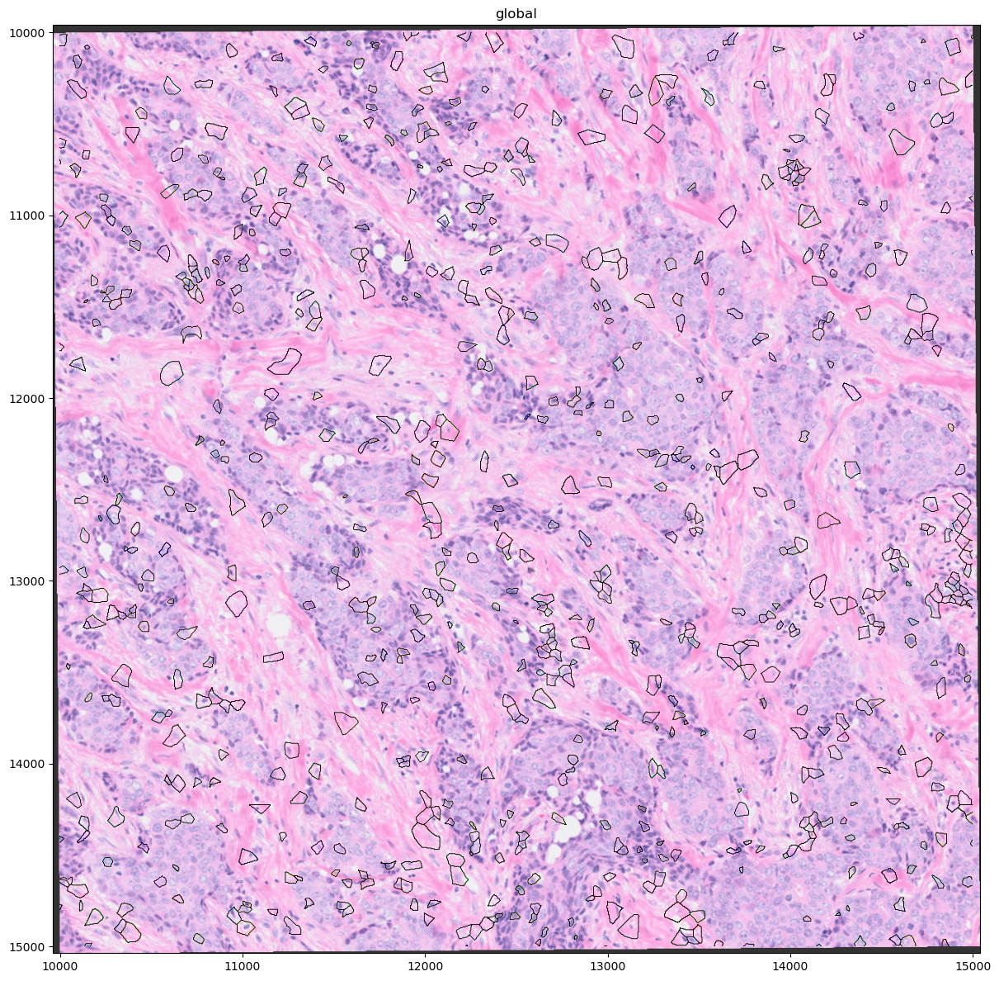

In [14]:
crop.pl.render_images("hne_2", alpha=0.8).pl.render_labels("cell_labels_subset", fill_alpha=0, outline_alpha=1).pl.show(figsize=(12, 12))

In [15]:
crop2 = crop.query.bounding_box(
    axes=["x", "y"],
    min_coordinate=[11000, 11000],
    max_coordinate=[14000, 14000],
    target_coordinate_system="global",
)
crop2

/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/functools.py:909: UserWarning: The object has `points` element. Depending on the number of points, querying MAY suffer from performance issues. Please consider filtering the object before calling this function by calling the `subset()` method of `SpatialData`.
  return dispatch(args[0].__class__)(*args, **kw)


SpatialData object
├── Images
│     ├── 'hne': DataTree[cyx] (3, 2346, 2346), (3, 1172, 1173), (3, 587, 586), (3, 293, 293)
│     ├── 'hne_2': DataTree[cyx] (3, 3000, 3000), (3, 1500, 1500), (3, 751, 750), (3, 374, 375)
│     ├── 'morphology_focus': DataTree[cyx] (1, 3000, 3000), (1, 1500, 1500), (1, 750, 750), (1, 375, 375), (1, 188, 188)
│     └── 'morphology_mip': DataTree[cyx] (1, 3000, 3000), (1, 1500, 1500), (1, 750, 750), (1, 375, 375), (1, 188, 188)
├── Labels
│     ├── 'cell_labels': DataTree[yx] (3000, 3000), (1500, 1500), (750, 750), (375, 375), (188, 188)
│     ├── 'cell_labels_subset': DataTree[yx] (3000, 3000), (1500, 1500), (750, 750), (375, 375), (188, 188)
│     └── 'nucleus_labels': DataTree[yx] (3000, 3000), (1500, 1500), (750, 750), (375, 375), (188, 188)
├── Points
│     └── 'transcripts': DataFrame with shape: (<Delayed>, 8) (3D points)
├── Shapes
│     ├── 'cell_boundaries': GeoDataFrame shape: (3318, 1) (2D shapes)
│     ├── 'cell_circles': GeoDataFrame shape: (